# Urban regreening & cooling — parks (Bengaluru)

All the analysis steps are written once as **functions** (Sections 2–4) and then run for each site in Section 5. Use **Runtime → Run all**.

- Site settings, dates and controls are in **Section 1**.
- If one site fails (for example, its boundary isn't found), the error is printed and the notebook moves on to the next site.
- **Main test:** scene-level difference-in-differences of each zone against its own neighbourhood (the 1–2 km ring, `control_local`), with standard errors clustered by year.
- Section 6 compares the sites and runs a **pooled model** across all parks.

Runtime is roughly 5–15 minutes per site.

## 0. Install & connect to Earth Engine

In [1]:
!pip install -q earthengine-api geemap osmnx

In [2]:
import ee

PROJECT_ID = 'deft-return-507617-v4'

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()            # opens a sign-in link the first time
    ee.Initialize(project=PROJECT_ID)
print('Earth Engine ready:', PROJECT_ID)

Earth Engine ready: deft-return-507617-v4


In [3]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import requests
from shapely.geometry import mapping, Point
from scipy.stats import mannwhitneyu, linregress
import geemap
import time
import traceback
from types import SimpleNamespace
import statsmodels.formula.api as smf
from IPython.display import display, Markdown

ox.settings.use_cache = True
ox.settings.log_console = False

# Save outputs to Google Drive when running in Colab, so they survive a runtime reset
BASE = '.'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/bengaluru_regreening'
except ImportError:
    pass
for d in ['data/sites', 'data/extracted', 'figures']:
    os.makedirs(os.path.join(BASE, d), exist_ok=True)
print('Outputs go to:', os.path.abspath(BASE))

Mounted at /content/drive
Outputs go to: /content/drive/MyDrive/bengaluru_regreening


## 1. Sites & settings

- `search_point` is an **approximate** location used only to search OpenStreetMap for the real polygon.
- `start` and `end` are the project start and completion years. **Verify them.**
- **Controls:** add 1–2 lakes or open areas per site that were *not* regreened in the same years.
- To correct a boundary, edit or replace `data/sites/<key>.geojson`. A saved file always takes priority over the OSM search.

In [4]:
SITES = {
    'freedom_park': dict(
        name='Freedom Park', search_point=(12.9774, 77.5796), search_radius=1000,
        keywords=['freedom park'], osm_query='Freedom Park, Seshadri Road, Bengaluru, Karnataka, India',
        start=2002, end=2008, controls=[]),     # old Central Jail -> park, opened Nov 2008
    'jp_park': dict(
        name='JP Park (Mathikere)', search_point=(13.0270, 77.5470), search_radius=2000,
        keywords=['jp park', 'j p park', 'j.p. park', 'j. p. park', 'jayaprakash', 'jaya prakash'],
        osm_query='JP Park, Mathikere, Bengaluru, Karnataka, India',
        start=2003, end=2006, controls=[]),     # opened 2006; start year: verify
    'jb_kaval': dict(
        name='JB Kaval Tree Park (Yelahanka)', search_point=(13.1250, 77.5482), search_radius=2000,
        keywords=['jarakabande', 'jb kaval', 'j b kaval', 'tree park'],
        osm_query='JB Kaval Tree Park, Yelahanka, Bengaluru, Karnataka, India',
        start=2014, end=2015, controls=[]),     # developed 2015; start year: verify
    'kadugodi': dict(
        name='Kadugodi Tree Park', search_point=(12.9990, 77.7600), search_radius=3000,
        keywords=['kadugodi', 'tree park'], osm_query='Kadugodi Tree Park, Bengaluru, Karnataka, India',
        start=2020, end=2021, controls=[]),     # verify dates
}

# Control template (put inside a site's `controls` list):
# dict(key='xyz_lake', name='XYZ Lake', search_point=(lat, lon), search_radius=1500,
#      keywords=['xyz'], osm_query='XYZ Lake, Bengaluru, Karnataka, India')

CITY_QUERY = 'Bengaluru, Karnataka, India'
MONTHS = (1, 4)                 # Jan-Apr (dry season)
RINGS = [(0, 100), (100, 300), (300, 500)]
MAX_SCENE_CLOUD = 60            # scene-level cloud % filter
MIN_ZONE_VALID = 0.6            # >= 60% of a zone's pixels must be clear in a scene
MIN_CITY_VALID = 0.6            # >= 60% of the city must be clear (for a fair city median)
MIN_SCENES_PER_YEAR = 3         # years with fewer clear scenes are flagged
LAST_YEAR = 2026

# Local control: the 1-2 km ring around each park (same scenes, same neighbourhood, not regreened).
# Every zone is compared against it in the scene-level test. Extra hand-picked controls can still go in `controls`.
LOCAL_CONTROL_RING = (1000, 2000)

## 2. Helper functions — boundaries & Landsat

In [5]:
WANTED_TAGS = {'natural': ['water', 'wetland', 'wood'], 'water': True,
               'leisure': ['park', 'nature_reserve', 'garden'],
               'landuse': ['forest', 'recreation_ground', 'reservoir', 'basin', 'grass']}
UTM = 32643   # UTM zone 43N, metres

def _pick_largest(gdf):
    if gdf is None or gdf.empty:
        return None
    gdf = gdf[gdf.geometry.geom_type.isin(['Polygon', 'MultiPolygon'])]
    if gdf.empty:
        return None
    return gdf.iloc[[int(gdf.to_crs(UTM).area.values.argmax())]]

def _search_nearby(spec):
    try:
        feats = ox.features_from_point(spec['search_point'], tags=WANTED_TAGS,
                                       dist=spec.get('search_radius', 1500))
    except Exception as e:
        print('   nearby search failed:', e)
        return None
    names = pd.Series('', index=feats.index)
    for col in ['name', 'name:en', 'alt_name']:
        if col in feats.columns:
            names = names + ' ' + feats[col].fillna('').astype(str).str.lower()
    hit = feats[names.apply(lambda n: any(k in n for k in spec['keywords']))]
    return _pick_largest(hit)

def _geocode(spec):
    try:
        g = ox.geocode_to_gdf(spec['osm_query'])
    except Exception as e:
        print('   geocoder failed:', e)
        return None
    cls = str(g.iloc[0].get('class', ''))
    if cls not in ('natural', 'water', 'leisure', 'landuse'):
        print(f'   geocoder returned a {cls!r} feature, not a lake/park - ignored')
        return None
    lat, lon = spec['search_point']
    d = (gpd.GeoSeries([g.geometry.iloc[0].centroid], crs=4326).to_crs(UTM).iloc[0]
         .distance(gpd.GeoSeries([Point(lon, lat)], crs=4326).to_crs(UTM).iloc[0]))
    if d > 5000:
        print(f'   geocoder result is {d/1000:.1f} km from the expected location - ignored')
        return None
    return _pick_largest(g)

def fetch_boundary(key, spec):
    path = os.path.join(BASE, 'data', 'sites', f'{key}.geojson')
    if os.path.exists(path):
        print(f'{key}: loaded saved boundary ({path})')
        return gpd.read_file(path).to_crs(4326)
    print(f'{key}: searching OpenStreetMap...')
    gdf, src = _search_nearby(spec), 'OSM nearby search'
    if gdf is None:
        gdf, src = _geocode(spec), 'OSM geocoder'
    if gdf is None:
        raise RuntimeError(f'No boundary found for {key}. Fix search_point/keywords, '
                           f'or draw the polygon (e.g. geojson.io) and save it as {path}')
    out = gpd.GeoDataFrame({'key': [key], 'name': [spec['name']], 'source': [src]},
                           geometry=[gdf.geometry.iloc[0]], crs=4326)
    out.to_file(path, driver='GeoJSON')
    print(f'   found via {src}; saved to {path}')
    return out

def fetch_city():
    path = os.path.join(BASE, 'data', 'sites', 'city_bengaluru.geojson')
    if os.path.exists(path):
        return gpd.read_file(path).to_crs(4326)
    g = ox.geocode_to_gdf(CITY_QUERY)
    out = gpd.GeoDataFrame({'name': ['Bengaluru']},
                           geometry=[g.geometry.iloc[0].simplify(0.0005)], crs=4326)
    out.to_file(path, driver='GeoJSON')
    return out

area_ha = lambda gdf: gdf.to_crs(UTM).area.iloc[0] / 1e4
to_ee = lambda gdf: ee.Geometry(mapping(gdf.geometry.iloc[0]))

In [6]:
BANDS = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'lst']
L89 = ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ST_B10']
L57 = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ST_B6']

def prep(img, src, sensor):
    qa = img.select('QA_PIXEL')
    clear = (qa.bitwiseAnd(1 << 1).eq(0)        # dilated cloud
             .And(qa.bitwiseAnd(1 << 3).eq(0))  # cloud
             .And(qa.bitwiseAnd(1 << 4).eq(0))) # shadow
    st = img.select(src[6])
    sr = img.select(src[:6]).multiply(0.0000275).add(-0.2)
    lst = st.multiply(0.00341802).add(149.0).subtract(273.15)
    out = sr.addBands(lst).rename(BANDS).updateMask(clear).updateMask(st.gt(0))
    out = out.addBands([out.normalizedDifference(['nir', 'red']).rename('ndvi'),
                        out.normalizedDifference(['swir1', 'nir']).rename('ndbi'),
                        out.normalizedDifference(['green', 'swir1']).rename('mndwi')])
    return ee.Image(out.copyProperties(img, ['system:time_start'])).set({
        'sensor': sensor, 'date': img.date().format('YYYY-MM-dd'),
        'year': img.date().get('year'), 'cloud': img.get('CLOUD_COVER'),
        'path': img.get('WRS_PATH'), 'row': img.get('WRS_ROW')})

def landsat(region, y0, y1):
    d0, d1 = f'{y0}-01-01', f'{y1 + 1}-01-01'
    def coll(cid, src, sensor, a, b):
        return (ee.ImageCollection(cid).filterBounds(region).filterDate(a, b)
                .filter(ee.Filter.calendarRange(MONTHS[0], MONTHS[1], 'month'))
                .filter(ee.Filter.lt('CLOUD_COVER', MAX_SCENE_CLOUD))
                .map(lambda i: prep(i, src, sensor)))

    # Initialize with Landsat 5
    c = coll('LANDSAT/LT05/C02/T1_L2', L57, 'L5', d0, d1)

    # Only add Landsat 7 if the start date is before 2013-01-01 to prevent inverted ranges
    if y0 < 2013:
        l7_end = f"{min(y1 + 1, 2013)}-01-01"
        c = c.merge(coll('LANDSAT/LE07/C02/T1_L2', L57, 'L7', d0, l7_end))

    c = c.merge(coll('LANDSAT/LC08/C02/T1_L2', L89, 'L8', d0, d1))
    c = c.merge(coll('LANDSAT/LC09/C02/T1_L2', L89, 'L9', d0, d1))
    return c.sort('system:time_start')

In [7]:
STAT_BANDS = ['lst', 'ndvi', 'ndbi', 'mndwi']

V_LST = {'min': -5, 'max': 5, 'palette': ['313695', '74add1', 'ffffbf', 'f46d43', 'a50026']}
V_DIFF = {'min': -3, 'max': 3, 'palette': ['2166ac', 'f7f7f7', 'b2182b']}
V_NDVI = {'min': 0, 'max': 0.7, 'palette': ['a50026', 'fee08b', '1a9850']}

def base_map(c):
    lat, lon = c.S['search_point']
    try:
        return geemap.Map(center=[lat, lon], zoom=15, basemap='Esri.WorldImagery')
    except Exception:
        mm = geemap.Map(center=[lat, lon], zoom=15)
        mm.add_basemap('SATELLITE')
        return mm

def save_csv(c, df, name, **kw):
    df.to_csv(os.path.join(BASE, 'data/extracted', f'{c.key}_{name}.csv'), **kw)

def fig_path(c, name):
    return os.path.join(BASE, 'figures', f'{c.key}_{name}.png')

def boot_ci(a, b, n=5000, seed=0):
    rng = np.random.default_rng(seed)
    d = [rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(n)]
    return np.percentile(d, [2.5, 97.5])

def per_km2(img):     # value per native pixel -> value per km2
    return img.divide(ee.Image.pixelArea().reproject(img.projection()).divide(1e6))

## 3. Analysis steps (one function per step)

Each function takes `c`, which holds everything for one site, and stores its results back on `c`.

In [8]:
def setup_site(key):
    S = SITES[key]
    c = SimpleNamespace(key=key, S=S)
    c.year_min = S['start'] - 5
    c.year_max = min(S['end'] + 5, LAST_YEAR)
    c.period_of = lambda y: 'before' if y < S['start'] else ('during' if y <= S['end'] else 'after')
    print(f"{S['name']}: before {c.year_min}-{S['start']-1} | during {S['start']}-{S['end']} "
          f"| after {S['end']+1}-{c.year_max}")
    return c

def load_boundaries(c):
    c.site_gdf = fetch_boundary(c.key, c.S)
    c.ctrl_gdfs = {k['key']: fetch_boundary(k['key'], k) for k in c.S['controls']}
    c.city_gdf = fetch_city()
    print(f"\nSite area: {area_ha(c.site_gdf):.1f} ha  (needs >= ~5 ha for Landsat thermal)")
    for k, g in c.ctrl_gdfs.items():
        print(f'Control {k}: {area_ha(g):.1f} ha')
    print(f'City area: {area_ha(c.city_gdf)/100:.0f} km2  (BBMP is roughly 700-750 km2; '
          'if this is far off, the geocoder picked the district - replace city_bengaluru.geojson)')

def build_zones(c):
    c.site_geom = to_ee(c.site_gdf)
    c.city_full = to_ee(c.city_gdf)
    c.city_geom = c.city_full.difference(c.site_geom.buffer(500, 1), 1)   # city baseline excludes the study area
    c.zones = [('site', c.site_geom)]
    for a, b in RINGS:
        inner = c.site_geom if a == 0 else c.site_geom.buffer(a, 1)
        c.zones.append((f'ring_{a}_{b}', c.site_geom.buffer(b, 1).difference(inner, 1)))
    a, b = LOCAL_CONTROL_RING
    c.zones.append(('control_local', c.site_geom.buffer(b, 1).difference(c.site_geom.buffer(a, 1), 1)))
    for k, g in c.ctrl_gdfs.items():
        c.zones.append((f'control_{k}', to_ee(g)))
    c.zone_order = [z for z, _ in c.zones]
    c.zone_fc = ee.FeatureCollection([ee.Feature(g, {'zone': z}) for z, g in c.zones])
    areas = c.zone_fc.map(lambda f: f.set('area_ha', f.geometry().area(1).divide(1e4)))
    display(pd.DataFrame({'zone': areas.aggregate_array('zone').getInfo(),
                          'area_ha': np.round(areas.aggregate_array('area_ha').getInfo(), 1)}))

def show_zone_map(c):
    m = base_map(c)
    colors = {'site': 'yellow', 'ring_0_100': 'orange', 'ring_100_300': 'red', 'ring_300_500': 'purple',
              'control_local': 'white'}
    for z, g in c.zones:
        m.addLayer(ee.FeatureCollection([ee.Feature(g)]).style(
            color=colors.get(z, 'cyan'), fillColor='00000000', width=2), {}, z)
    m.add_layer_control()
    display(m)   # check that the yellow outline matches the real site

def check_availability(c):
    col_all = landsat(c.site_geom, c.year_min, c.year_max)
    avail = pd.DataFrame(ee.Dictionary({
        'year': col_all.aggregate_array('year'), 'sensor': col_all.aggregate_array('sensor'),
        'path': col_all.aggregate_array('path'), 'row': col_all.aggregate_array('row')}).getInfo())
    print('Scenes per year & sensor (before per-pixel cloud masking):')
    display(pd.crosstab(avail.year, avail.sensor, margins=True))
    print('WRS path/row used:', sorted(set(zip(avail.path, avail.row))))

In [9]:
def make_scene_stats(zone_fc, city_geom):
    def scene_stats(img):
        valid = (ee.Image.constant(1).updateMask(img.select('lst').mask())
                 .unmask(0).rename('valid'))                       # 1 = clear pixel
        city = img.select(['lst', 'ndvi']).addBands(valid).reduceRegion(
            reducer=ee.Reducer.median().combine(ee.Reducer.mean(), sharedInputs=True),
            geometry=city_geom, scale=100, maxPixels=1e9, tileScale=4)
        fc = img.select(STAT_BANDS).addBands(valid).reduceRegions(
            collection=zone_fc, reducer=ee.Reducer.mean(), scale=30, tileScale=4)
        return fc.map(lambda f: ee.Feature(None, f.toDictionary()).set({
            'date': img.get('date'), 'year': img.get('year'), 'sensor': img.get('sensor'),
            'scene_cloud': img.get('cloud'),
            'city_lst_median': city.get('lst_median'), 'city_ndvi_median': city.get('ndvi_median'),
            'city_valid': city.get('valid_mean')}))
    return scene_stats

def get_with_retry(fn, label, tries=4, wait=5):
    """Call fn(); on Earth Engine errors wait and retry with a growing delay. Returns None if all tries fail."""
    for attempt in range(tries):
        try:
            return fn()
        except Exception as e:
            print(f'   {label}: attempt {attempt+1} failed ({str(e)[:70]}); waiting {wait}s')
            time.sleep(wait)
            wait *= 2
    return None

def extract_scenes(c):
    scene_stats = make_scene_stats(c.zone_fc, c.city_geom)
    rows, lost = [], 0
    for y in range(c.year_min, c.year_max + 1):
        col = landsat(c.site_geom, y, y)
        n = col.size().getInfo()
        if n == 0:
            print(y, ': no scenes')
            continue
        feats = get_with_retry(
            lambda: ee.FeatureCollection(col.map(scene_stats)).flatten().getInfo()['features'],
            f'{y}', tries=3)
        if feats is None:
            # Fall back to one scene at a time, so a busy server can't wipe out a whole year
            print(f'   {y}: fetching one scene at a time')
            imgs, feats = col.toList(n), []
            for i in range(n):
                f_i = get_with_retry(lambda i=i: scene_stats(ee.Image(imgs.get(i))).getInfo()['features'],
                                     f'{y} scene {i+1}/{n}', tries=5)
                if f_i is None:
                    lost += 1
                else:
                    feats += f_i
        rows += [f['properties'] for f in feats]
        print(y, ':', len(feats) // len(c.zone_order), 'of', n, 'scenes extracted')
        time.sleep(1.5)   # stay under Earth Engine's request limits
    c.df_scenes = pd.DataFrame(rows)
    save_csv(c, c.df_scenes, 'scenes', index=False)
    print('Saved', len(c.df_scenes), 'rows', f'| ⚠️ {lost} scenes could not be fetched' if lost else '')

def annual_values(c):
    df = c.df_scenes.copy()
    for col in STAT_BANDS + ['valid', 'city_lst_median', 'city_ndvi_median', 'city_valid']:
        df[col] = pd.to_numeric(df[col], errors='coerce') if col in df else np.nan
    df['year'] = df['year'].astype(int)

    good = df[(df.valid >= MIN_ZONE_VALID) & (df.city_valid >= MIN_CITY_VALID)
              & df.lst.notna() & df.city_lst_median.notna()].copy()
    good['lst_anom'] = good.lst - good.city_lst_median          # +ve = hotter than city
    good['ndvi_anom'] = good.ndvi - good.city_ndvi_median

    annual = (good.groupby(['zone', 'year'])
              .agg(lst=('lst', 'median'), lst_anom=('lst_anom', 'median'),
                   ndvi=('ndvi', 'median'), ndvi_anom=('ndvi_anom', 'median'),
                   ndbi=('ndbi', 'median'), mndwi=('mndwi', 'median'),
                   city_lst=('city_lst_median', 'median'),
                   n_scenes=('date', 'nunique'),
                   sensors=('sensor', lambda s: '+'.join(sorted(set(s)))))
              .reset_index())
    annual['period'] = annual.year.apply(c.period_of)
    annual['low_n'] = annual.n_scenes < MIN_SCENES_PER_YEAR
    c.annual = annual
    c.good = good
    c.use = annual[~annual.low_n]
    save_csv(c, annual, 'annual', index=False)
    print('Clear scenes kept per year (site zone):')
    display(annual[annual.zone == 'site'][['year', 'period', 'n_scenes', 'sensors', 'lst_anom', 'ndvi', 'mndwi']].round(3))

In [10]:
def period_summary(c):
    use = c.use
    pv = use.pivot_table(index='zone', columns='period', values='lst_anom', aggfunc='mean').reindex(c.zone_order)
    for p in ['before', 'during', 'after']:
        if p not in pv:
            pv[p] = np.nan
    pv = pv[['before', 'during', 'after']]
    pv['change'] = pv['after'] - pv['before']
    for z in c.zone_order:
        if z.startswith('control_'):
            pv[f'DiD_vs_{z[8:]}'] = pv['change'] - pv.loc[z, 'change']

    nd = use.pivot_table(index='zone', columns='period', values='ndvi', aggfunc='mean').reindex(c.zone_order)
    pv['ndvi_change'] = nd.get('after') - nd.get('before')
    mw = use.pivot_table(index='zone', columns='period', values='mndwi', aggfunc='mean').reindex(c.zone_order)
    pv['mndwi_change'] = mw.get('after') - mw.get('before')

    # Internal contrast: how much cooler is the site than its own 300-500 m ring?
    if 'ring_300_500' in pv.index:
        print('Site minus 300-500 m ring (°C):',
              {p: round(pv.loc['site', p] - pv.loc['ring_300_500', p], 2) for p in ['before', 'after']})
    c.pv = pv
    save_csv(c, pv.round(3), 'period_summary')
    display(pv.round(3))

def significance(c):
    use, stats = c.use, []
    for z in c.zone_order:
        a = use[(use.zone == z) & (use.period == 'before')].lst_anom.values
        b = use[(use.zone == z) & (use.period == 'after')].lst_anom.values
        if len(a) < 2 or len(b) < 2:
            stats.append(dict(zone=z, n_before=len(a), n_after=len(b)))
            continue
        lo, hi = boot_ci(a, b)
        stats.append(dict(zone=z, n_before=len(a), n_after=len(b), change=b.mean() - a.mean(),
                          ci_low=lo, ci_high=hi,
                          mannwhitney_p=mannwhitneyu(a, b, alternative='two-sided').pvalue))
    c.stats = pd.DataFrame(stats)
    save_csv(c, c.stats.round(3), 'stats', index=False)
    print('Significant if the CI excludes 0 and p < 0.05 (only ~5 years per period, so treat with caution)')
    display(c.stats.round(3))

def scene_level_test(c, control='control_local'):
    """Main test. For every clear scene: d = zone LST - control LST (same scene, so weather cancels).
    Then OLS  d ~ post  (post = 1 after the project, 0 before; 'during' years dropped),
    with standard errors clustered by year (scenes in the same year are not independent)."""
    g = c.good.copy()
    g['period'] = g.year.map(c.period_of)
    g = g[g.period.isin(['before', 'after'])]
    g['post'] = (g.period == 'after').astype(int)
    wide = g.pivot_table(index=['date', 'year', 'post'], columns='zone', values='lst').reset_index()
    if control not in wide:
        print(f'No {control} values - cannot run the scene-level test.')
        c.scene_did, c.scene_rows = pd.DataFrame(), pd.DataFrame()
        return
    out, long = [], []
    for z in [z for z in c.zone_order if z != control]:
        if z not in wide:
            continue
        d = wide[['date', 'year', 'post', z, control]].dropna().copy()
        d['diff'] = d[z] - d[control]
        if d.post.nunique() < 2 or d.year.nunique() < 4:
            out.append(dict(zone=z, note='not enough before/after scenes'))
            continue
        fit = smf.ols('diff ~ post', d).fit(cov_type='cluster', cov_kwds={'groups': d.year}, use_t=True)
        lo, hi = fit.conf_int().loc['post']
        out.append(dict(zone=z, scenes_before=int((d.post == 0).sum()), scenes_after=int((d.post == 1).sum()),
                        years=d.year.nunique(), did=fit.params['post'], ci_low=lo, ci_high=hi,
                        p=fit.pvalues['post']))
        long.append(d[['date', 'year', 'post', 'diff']].assign(zone=z))
    c.scene_did = pd.DataFrame(out)
    c.scene_rows = pd.concat(long) if long else pd.DataFrame()
    save_csv(c, c.scene_did.round(4), 'scene_did', index=False)
    print(f'did = change in (zone − {control}) after vs before, °C. Negative = the zone cooled relative to '
          'its neighbourhood. Significant if p < 0.05 (CI excludes 0).')
    display(c.scene_did.round(3))

def veg_water_regression(c):
    r = c.use[~c.use.zone.str.startswith('control_')].dropna(subset=['lst_anom', 'ndvi_anom', 'mndwi'])
    lr = linregress(r.ndvi_anom, r.lst_anom)
    print(f'LST anomaly vs NDVI anomaly: slope {lr.slope/10:.2f} °C per +0.1 NDVI, R² = {lr.rvalue**2:.2f}, p = {lr.pvalue:.3g}')
    X = np.column_stack([np.ones(len(r)), r.ndvi_anom, r.mndwi])
    coef, *_ = np.linalg.lstsq(X, r.lst_anom, rcond=None)
    pred = X @ coef
    r2 = 1 - ((r.lst_anom - pred) ** 2).sum() / ((r.lst_anom - r.lst_anom.mean()) ** 2).sum()
    print(f'LST anomaly ~ NDVI anomaly + MNDWI: {coef[1]/10:.2f} °C per +0.1 NDVI, '
          f'{coef[2]/10:.2f} °C per +0.1 MNDWI, R² = {r2:.2f}')
    c.ndvi_slope = lr.slope / 10

In [11]:
def covariates(c):
    wp_years = [y for y in range(c.year_min, c.year_max + 1) if 2000 <= y <= 2020]
    epochs = sorted({e for e in range(1975, 2031, 5) if c.year_min - 5 < e <= c.year_max + 4})

    wp = ee.ImageCollection('WorldPop/GP/100m/pop').filter(ee.Filter.eq('country', 'IND'))
    layers = [per_km2(wp.filter(ee.Filter.eq('year', y)).first().select('population')).rename(f'wp_{y}')
              for y in wp_years]
    for e in epochs:
        pop = ee.Image(f'JRC/GHSL/P2023A/GHS_POP/{e}').select('population_count')
        blt = ee.Image(f'JRC/GHSL/P2023A/GHS_BUILT_S/{e}').select('built_surface')
        layers += [per_km2(pop).rename(f'ghspop_{e}'),
                   blt.divide(ee.Image.pixelArea().reproject(blt.projection())).rename(f'built_{e}')]

    res = ee.Image.cat(layers).reduceRegions(c.zone_fc, ee.Reducer.mean(), scale=30, tileScale=4).getInfo()
    recs = []
    for f in res['features']:
        p = f['properties']
        for k, v in p.items():
            if k == 'zone' or v is None:
                continue
            src_, yr = k.rsplit('_', 1)
            recs.append(dict(zone=p['zone'], source=src_, year=int(yr), value=v))
    c.cov = pd.DataFrame(recs)
    save_csv(c, c.cov, 'covariates', index=False)
    print('wp / ghspop = people per km2, built = built-up fraction (0-1)')
    display(c.cov.pivot_table(index=['source', 'year'], columns='zone', values='value')
            .reindex(columns=c.zone_order).round(2))

def climate(c):
    def climate_year(y):
        y = ee.Number(y)
        d0 = ee.Date.fromYMD(y, 1, 1)
        chirps = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation')
        era = ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR').select('temperature_2m')
        mean = lambda img, sc: img.reduceRegion(ee.Reducer.mean(), c.city_full, sc, maxPixels=1e9).values().get(0)
        return ee.Feature(None, {
            'year': y,
            'rain_annual_mm': mean(chirps.filterDate(d0, d0.advance(1, 'year')).sum(), 5566),
            'rain_janapr_mm': mean(chirps.filterDate(d0, d0.advance(4, 'month')).sum(), 5566),
            't2m_janapr_c': ee.Number(mean(era.filterDate(d0, d0.advance(4, 'month')).mean(), 11132)).subtract(273.15)})

    clim = pd.DataFrame([f['properties'] for f in ee.FeatureCollection(
        ee.List.sequence(c.year_min, c.year_max).map(climate_year)).getInfo()['features']])
    clim['year'] = clim.year.astype(int)
    city_lst = c.annual[c.annual.zone == 'site'][['year', 'city_lst']]
    c.clim = clim.merge(city_lst, on='year', how='left')
    save_csv(c, c.clim, 'climate', index=False)
    display(c.clim.round(2))

In [12]:
def charts(c):
    S, annual, stats, cov = c.S, c.annual, c.stats, c.cov
    shade = lambda ax: ax.axvspan(S['start'] - 0.5, S['end'] + 0.5, color='grey', alpha=0.15, label='during')

    # 1. LST anomaly over time, by zone
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for z in c.zone_order:
        d = annual[annual.zone == z]
        ax.plot(d.year, d.lst_anom, marker='o', label=z, lw=2.5 if z == 'site' else 1.2,
                ls='--' if z.startswith('control_') else '-')
        lo = d[d.low_n]
        ax.scatter(lo.year, lo.lst_anom, facecolors='white', edgecolors='k', zorder=5)
    shade(ax); ax.axhline(0, color='k', lw=0.6)
    ax.set(title=f"{S['name']}: LST relative to city median (Jan–Apr)", xlabel='Year', ylabel='LST anomaly (°C)')
    ax.legend(fontsize=8, ncol=3); plt.tight_layout(); plt.savefig(fig_path(c, 'lst_timeseries'), dpi=200); plt.show()

    # 2. NDVI & MNDWI at the site
    fig, ax = plt.subplots(figsize=(10, 3.5))
    d = annual[annual.zone == 'site']
    ax.plot(d.year, d.ndvi, marker='o', color='green', label='NDVI')
    ax.plot(d.year, d.mndwi, marker='s', color='steelblue', label='MNDWI (water)')
    shade(ax); ax.set(title=f"{S['name']}: site vegetation & water", xlabel='Year', ylabel='Index'); ax.legend()
    plt.tight_layout(); plt.savefig(fig_path(c, 'ndvi_mndwi'), dpi=200); plt.show()

    # 3. Cooling vs distance (after - before)
    ok = stats.dropna(subset=['change']) if 'change' in stats else stats.iloc[0:0]
    if not ok.empty:
        s = ok.set_index('zone').reindex([z for z in c.zone_order if z in set(ok.zone)])
        fig, ax = plt.subplots(figsize=(7, 4))
        ax.bar(s.index, s.change, yerr=[s.change - s.ci_low, s.ci_high - s.change], capsize=4,
               color=['tab:blue' if v < 0 else 'tab:red' for v in s.change])
        ax.axhline(0, color='k', lw=0.6)
        ax.set(title=f"{S['name']}: change in LST anomaly (after − before), 95% CI", ylabel='°C')
        plt.xticks(rotation=20); plt.tight_layout(); plt.savefig(fig_path(c, 'cooling_vs_distance'), dpi=200); plt.show()

    # 4. Population density around the site
    p = cov[cov.source == 'wp'].pivot(index='year', columns='zone', values='value') if not cov.empty else pd.DataFrame()
    if not p.empty:
        p.reindex(columns=[z for z in c.zone_order if z in p]).plot(marker='o', figsize=(9, 3.5),
            title=f"{S['name']}: population density (WorldPop, people/km²)")
        plt.tight_layout(); plt.savefig(fig_path(c, 'population'), dpi=200); plt.show()

def before_after_maps(c):
    S = c.S
    aoi = c.site_geom.buffer(1500, 10).bounds()

    def period_anomaly(y0, y1):
        comp = landsat(c.city_full, y0, y1).median()
        med = comp.select('lst').reduceRegion(ee.Reducer.median(), c.city_geom, 100, maxPixels=1e9).get('lst')
        return comp.select('lst').subtract(ee.Number(med)).rename('lst_anom'), comp.select('ndvi')

    before_lst, before_ndvi = period_anomaly(c.year_min, S['start'] - 1)
    after_lst, after_ndvi = period_anomaly(S['end'] + 1, c.year_max)
    diff = after_lst.subtract(before_lst)
    outline = ee.FeatureCollection([ee.Feature(c.site_geom)]).style(color='black', fillColor='00000000', width=2)

    m2 = base_map(c)
    m2.addLayer(before_lst.clip(aoi), V_LST, 'LST anomaly before')
    m2.addLayer(after_lst.clip(aoi), V_LST, 'LST anomaly after')
    m2.addLayer(diff.clip(aoi), V_DIFF, 'Change (after - before)')
    m2.addLayer(before_ndvi.clip(aoi), V_NDVI, 'NDVI before', False)
    m2.addLayer(after_ndvi.clip(aoi), V_NDVI, 'NDVI after', False)
    m2.addLayer(outline, {}, 'Site')
    m2.add_layer_control()

    # Save PNGs for the report
    for name, img, vis in [('map_lst_before', before_lst, V_LST), ('map_lst_after', after_lst, V_LST),
                           ('map_lst_change', diff, V_DIFF), ('map_ndvi_before', before_ndvi, V_NDVI),
                           ('map_ndvi_after', after_ndvi, V_NDVI)]:
        url = img.visualize(**vis).blend(outline).getThumbURL({'region': aoi, 'dimensions': 800, 'format': 'png'})
        with open(fig_path(c, name), 'wb') as fh:
            fh.write(requests.get(url).content)
    print('Saved map PNGs to figures/')
    display(m2)

def summary_line(c):
    sd = c.scene_did.set_index('zone') if len(c.scene_did) else pd.DataFrame()
    if 'site' not in sd.index or pd.isna(sd.loc['site'].get('did')):
        print(f"{c.S['name']}: not enough clear scenes before/after for the main test.")
        return
    r = sd.loc['site']
    sig = r.p < 0.05
    print(f"{c.S['name']}: relative to its 1-2 km neighbourhood, the park's LST changed by {r.did:+.2f} °C "
          f"after the project (95% CI {r.ci_low:+.2f} to {r.ci_high:+.2f}, p = {r.p:.3f}, "
          f"{int(r.scenes_before)}+{int(r.scenes_after)} scenes) - {'significant' if sig else 'not significant'}. "
          f"NDVI change {c.pv.loc['site', 'ndvi_change']:+.3f}.")

## 4. Run one site end to end

In [13]:
STEPS = [
    ('Boundaries from OpenStreetMap', load_boundaries),
    ('Zones (site, rings, controls)', build_zones),
    ('Map to check the zones', show_zone_map),
    ('Availability check — scenes per year', check_availability),
    ('Extraction — zone means & city median for every scene', extract_scenes),
    ('Quality filter, anomalies & yearly values', annual_values),
    ('Before vs after, cooling vs distance, DiD', period_summary),
    ('Significance (yearly values, before vs after)', significance),
    ('MAIN TEST: scene-level difference-in-differences vs neighbourhood', scene_level_test),
    ('How much does vegetation / water explain LST?', veg_water_regression),
    ('Covariates — population & built-up', covariates),
    ('Rainfall & air temperature', climate),
    ('Charts', charts),
    ('Before / after maps', before_after_maps),
    ('Summary', summary_line),
]

RESULTS = {}

def run_site(key):
    display(Markdown(f"---\n# {SITES[key]['name']}"))
    c = setup_site(key)
    RESULTS[key] = c
    for title, fn in STEPS:
        display(Markdown(f'### {title}'))
        try:
            fn(c)
        except Exception:
            print(f'❌ {key}: step "{title}" failed - skipping the rest of this site.')
            traceback.print_exc()
            c.failed_at = title
            break
    return c

## 5. Run each site

---
# Freedom Park

Freedom Park: before 1997-2001 | during 2002-2008 | after 2009-2013


### Boundaries from OpenStreetMap

freedom_park: loaded saved boundary (/content/drive/MyDrive/bengaluru_regreening/data/sites/freedom_park.geojson)

Site area: 5.6 ha  (needs >= ~5 ha for Landsat thermal)
City area: 717 km2  (BBMP is roughly 700-750 km2; if this is far off, the geocoder picked the district - replace city_bengaluru.geojson)


### Zones (site, rings, controls)

...

wp / ghspop = people per km2, built = built-up fraction (0-1)


zone             site  ring_0_100  ring_100_300  ring_300_500  control_local
source year                                                                 
built  1995      0.09        0.17          0.23          0.32           0.36
       2000      0.10        0.19          0.25          0.34           0.37
       2005      0.15        0.21          0.27          0.35           0.38
       2010      0.19        0.23          0.28          0.35           0.38
       2015      0.23        0.25          0.29          0.35           0.38
ghspop 1995   8087.35    16535.05      20112.84      21846.25       31533.54
       2000   9474.35    18445.31      22047.10      23215.64       31991.73
       2005  14440.60    21937.51      25158.75      25619.85       35326.65
       2010  19992.33    25626.79      28346.74      27970.43       38593.05
       2015  25808.75    29961.40      32176.45      31003.86       42989.24
wp     2000  21553.83    21599.01      23935.90      25653.82       27915.90
       2001  19977.77    20506.54      22948.27      24280.46       26407.38
       2002  18973.20    19017.14      22156.71      24046.65       27241.33
       2003  19830.28    20128.52      23415.59      24905.37       27574.57
       2004  20029.21    20044.39      23887.30      26169.36       29539.98
       2005  19340.19    19992.84      24053.06      26126.30       29381.07
       2006  19363.22    19961.09      24476.73      26748.13       31655.60
       2007  19426.47    19726.67      24609.72      27429.77       32535.96
       2008  21417.95    22621.28      26299.03      28323.17       32768.04
       2009  19643.08    20707.63      25628.67      28710.04       33173.34
       2010  25273.16    25896.23      28121.38      30109.31       32528.98
       2011  25246.08    25550.85      27996.14      30907.40       36339.91
       2012  27699.07    27348.72      29790.61      32427.99       37649.18
       2013  27999.59    27251.22      29887.73      33658.01       38397.60

### Rainfall & air temperature

,rain_annual_mm,rain_janapr_mm,t2m_janapr_c,year,city_lst
0,728.32,24.52,22.65,1997,30.06
1,1362.16,48.60,24.99,1998,27.31
2,1075.35,110.88,23.60,1999,33.25
3,1081.84,79.33,23.47,2000,40.19
4,1123.09,100.06,23.80,2001,36.19
5,726.03,20.51,23.93,2002,39.19
6,746.42,85.58,24.35,2003,37.25
7,1105.76,84.27,24.10,2004,38.81
8,1402.59,108.69,24.15,2005,35.44
9,815.84,62.72,23.25,2006,28.84


### Charts

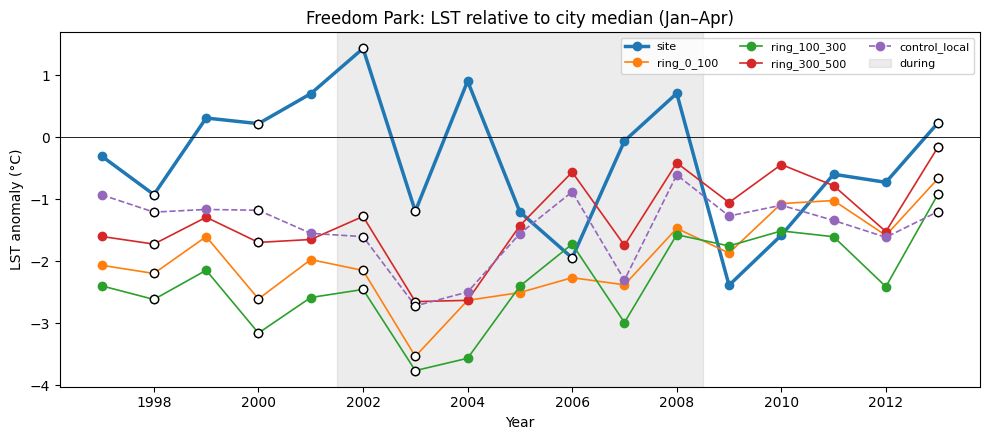

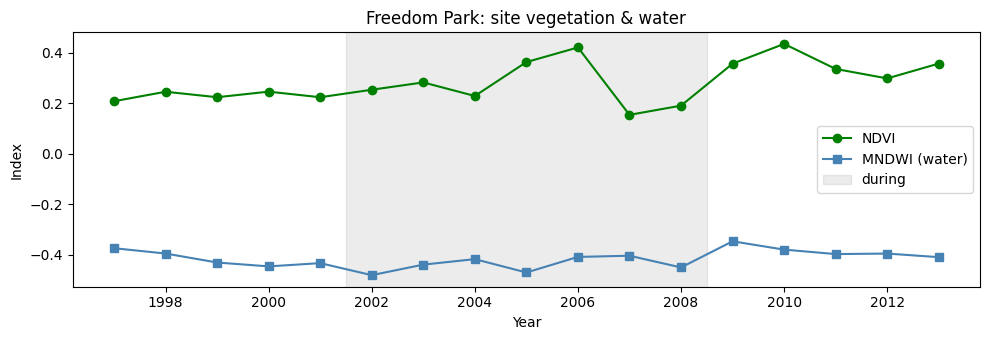

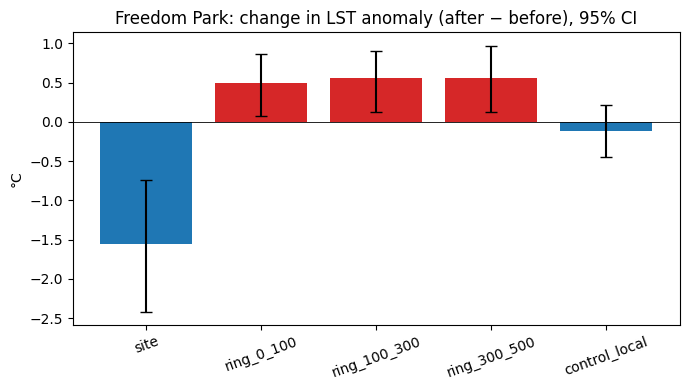

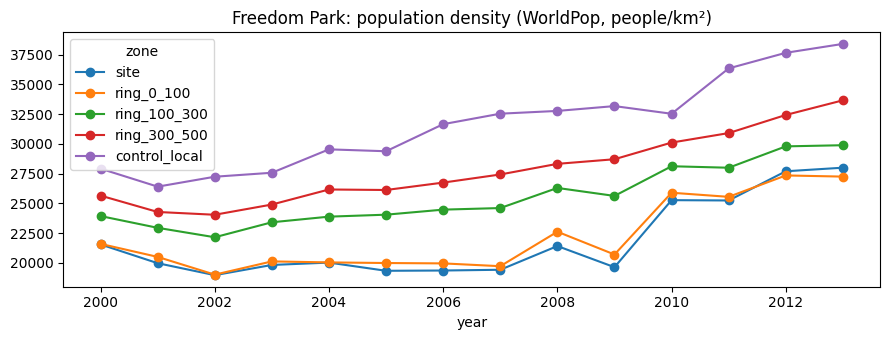

### Before / after maps

Saved map PNGs to figures/


Map(center=[12.9774, 77.5796], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topri…

### Summary

Freedom Park: relative to its 1-2 km neighbourhood, the park's LST changed by -1.32 °C after the project (95% CI -2.66 to +0.01, p = 0.052, 11+20 scenes) - not significant. NDVI change +0.138.


In [14]:
run_site('freedom_park');

---
# JP Park (Mathikere)

JP Park (Mathikere): before 1998-2002 | during 2003-2006 | after 2007-2011


### Boundaries from OpenStreetMap

jp_park: searching OpenStreetMap...
   found via OSM nearby search; saved to /content/drive/MyDrive/bengaluru_regreening/data/sites/jp_park.geojson

Site area: 29.0 ha  (needs >= ~5 ha for Landsat thermal)
City area: 717 km2  (BBMP is roughly 700-750 km2; if this is far off, the geocoder picked the district - replace city_bengaluru.geojson)


### Zones (site, rings, controls)

...

wp / ghspop = people per km2, built = built-up fraction (0-1)


zone             site  ring_0_100  ring_100_300  ring_300_500  control_local
source year                                                                 
built  1995      0.02        0.22          0.28          0.26           0.26
       2000      0.04        0.35          0.35          0.30           0.29
       2005      0.05        0.37          0.39          0.32           0.30
       2010      0.06        0.39          0.42          0.35           0.31
       2015      0.07        0.40          0.45          0.36           0.32
ghspop 1995   1687.82    18818.74      25129.00      22493.76       18275.77
       2000   3316.68    29140.53      31567.08      25195.31       19550.55
       2005   4368.84    33348.51      37977.64      29662.49       21944.41
       2010   5522.30    37671.56      45088.48      34939.10       24382.96
       2015   6860.27    42848.76      52970.71      40665.16       27446.08
wp     2000  13744.77    16062.42      17593.80      18900.75       20102.07
       2001  13172.92    18400.77      19829.48      21050.90       20019.22
       2002  13178.77    19298.33      21158.99      21837.18       20545.55
       2003  12286.11    19387.94      21580.10      22337.42       20790.13
       2004  13123.05    19534.80      22536.82      23349.14       21089.50
       2005  12058.39    19122.50      21797.37      22947.58       21550.28
       2006  12090.02    18595.45      21906.87      23082.64       21796.69
       2007  11800.11    18777.53      21944.08      22960.43       22731.07
       2008  13204.72    20037.24      22519.10      23479.25       23169.37
       2009  12505.90    21194.74      24742.27      25654.10       24503.21
       2010  12535.97    21052.08      25652.47      26381.65       24641.31
       2011  10874.51    19107.62      24395.04      26445.83       25322.17

### Rainfall & air temperature

,rain_annual_mm,rain_janapr_mm,t2m_janapr_c,year,city_lst
0,1362.16,48.60,24.99,1998,27.31
1,1075.35,110.88,23.60,1999,33.25
2,1081.84,79.33,23.47,2000,40.19
3,1123.09,100.06,23.80,2001,36.19
4,726.03,20.51,23.93,2002,39.19
5,746.42,85.58,24.35,2003,37.25
6,1105.76,84.27,24.10,2004,38.81
7,1402.59,108.69,24.15,2005,35.44
8,815.84,62.72,23.25,2006,32.31
9,1275.46,71.59,24.07,2007,37.44


### Charts

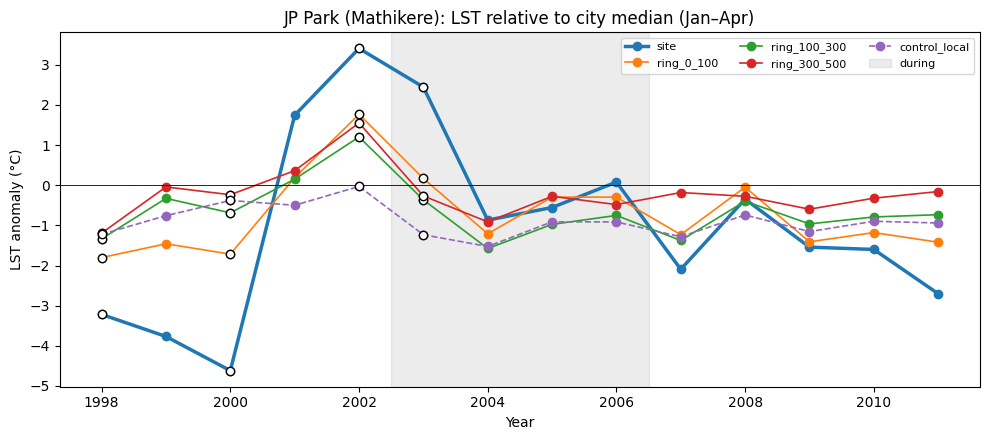

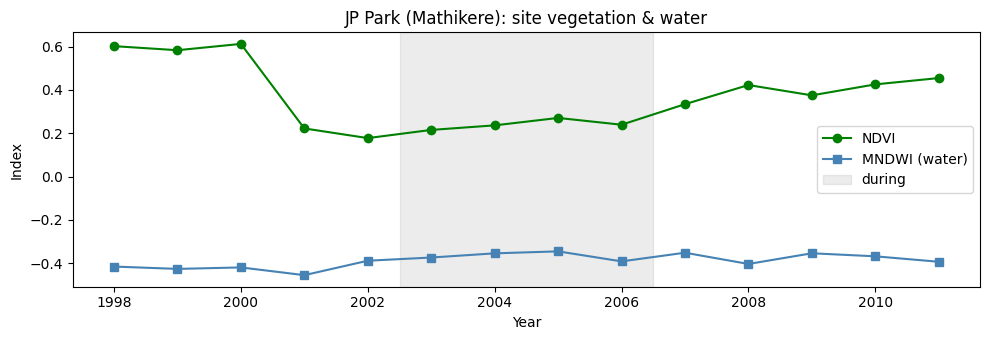

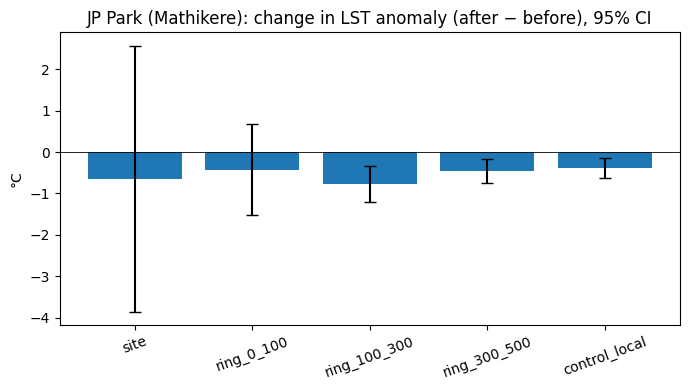

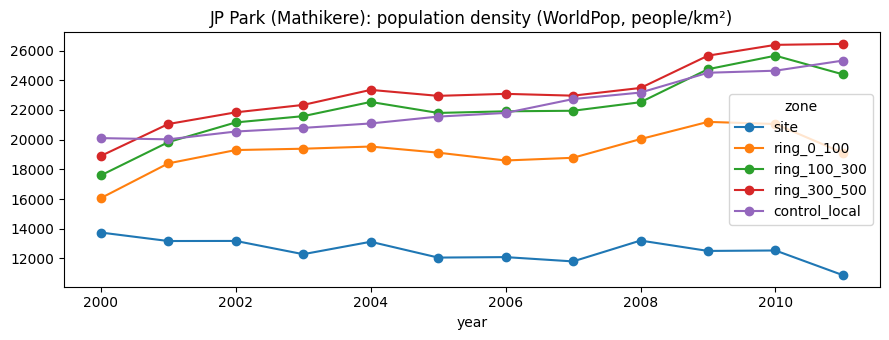

### Before / after maps

Saved map PNGs to figures/


Map(center=[13.027, 77.547], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprigh…

### Summary

JP Park (Mathikere): relative to its 1-2 km neighbourhood, the park's LST changed by -0.48 °C after the project (95% CI -3.79 to +2.82, p = 0.749, 10+34 scenes) - not significant. NDVI change -0.000.


In [15]:
run_site('jp_park');

---
# JB Kaval Tree Park (Yelahanka)

JB Kaval Tree Park (Yelahanka): before 2009-2013 | during 2014-2015 | after 2016-2020


### Boundaries from OpenStreetMap

jb_kaval: searching OpenStreetMap...
   found via OSM nearby search; saved to /content/drive/MyDrive/bengaluru_regreening/data/sites/jb_kaval.geojson

Site area: 2.2 ha  (needs >= ~5 ha for Landsat thermal)
City area: 717 km2  (BBMP is roughly 700-750 km2; if this is far off, the geocoder picked the district - replace city_bengaluru.geojson)


### Zones (site, rings, controls)

...

wp / ghspop = people per km2, built = built-up fraction (0-1)


zone            site  ring_0_100  ring_100_300  ring_300_500  control_local
source year                                                                
built  2005     0.01        0.02          0.01          0.01           0.01
       2010     0.01        0.03          0.02          0.01           0.02
       2015     0.02        0.04          0.03          0.01           0.04
       2020     0.02        0.04          0.04          0.03           0.05
ghspop 2005   141.84      453.31        307.51        130.21         535.52
       2010   304.28      770.89        477.57        234.39         984.37
       2015   440.18     1137.72        776.75        380.04        1507.90
       2020   516.85     1380.12       1213.30        806.10        2382.00
wp     2009  3356.92     3468.12       3390.09       3450.20        3880.00
       2010  5262.54     5573.56       5244.58       4441.00        4179.51
       2011  4093.39     4229.44       4070.24       3868.85        4181.42
       2012  3776.10     3845.37       3613.86       3116.47        3712.12
       2013  4019.42     4097.69       3901.56       3569.03        3933.82
       2014  4611.51     4762.51       4531.60       3940.01        4451.30
       2015  4434.92     4614.25       4397.97       4100.74        4826.37
       2016  4499.68     4674.82       4666.07       4469.87        5123.10
       2017  5100.16     5303.95       5245.71       5094.59        5646.34
       2018  5331.07     5326.09       5264.48       5164.18        5963.86
       2019  5410.64     5501.84       5532.29       5496.43        6312.02
       2020  5797.68     5974.92       6024.02       5878.01        6375.71

### Rainfall & air temperature

,rain_annual_mm,rain_janapr_mm,t2m_janapr_c,year,city_lst
0,1026.48,64.67,24.09,2009,33.69
1,1372.26,126.94,24.84,2010,30.94
2,1086.83,172.47,23.38,2011,34.88
3,873.21,97.43,24.29,2012,39.44
4,986.35,66.01,24.45,2013,40.06
5,1015.68,32.04,24.06,2014,37.06
6,1091.14,149.79,23.48,2015,36.75
7,655.45,24.81,24.84,2016,40.75
8,1320.22,53.10,24.33,2017,39.69
9,913.03,90.13,23.47,2018,35.69


### Charts

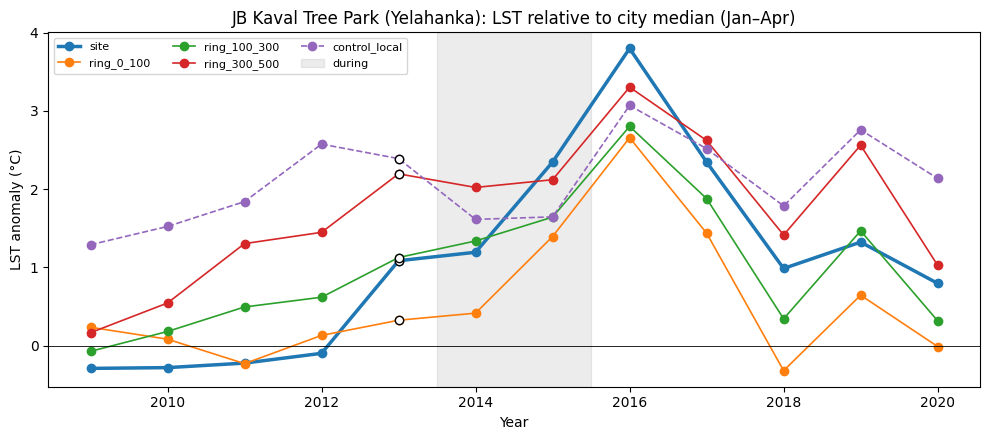

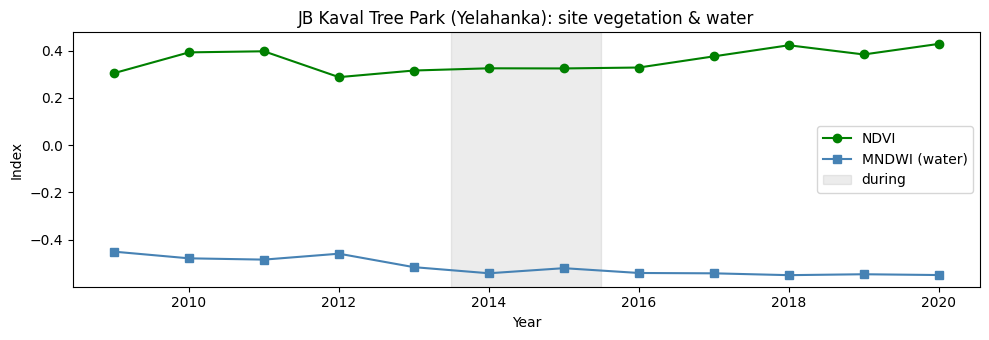

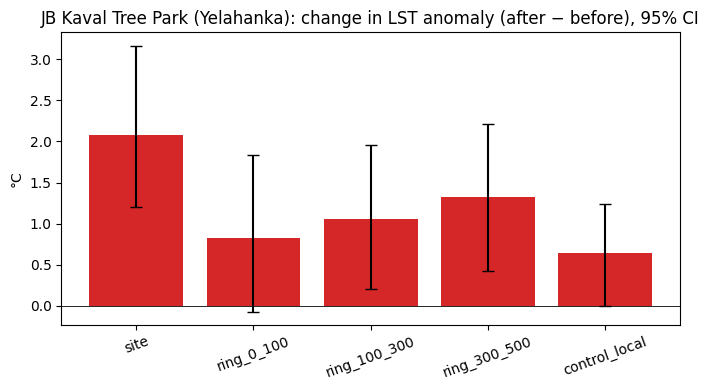

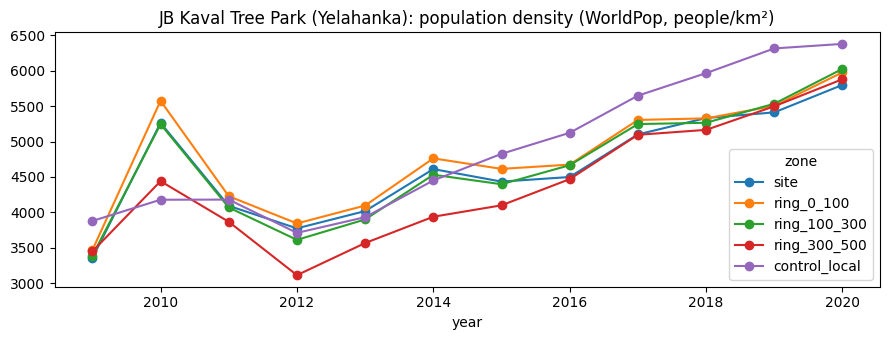

### Before / after maps

Saved map PNGs to figures/


Map(center=[13.125, 77.5482], controls=(WidgetControl(options=['position', 'transparent_bg'], position='toprig…

### Summary

JB Kaval Tree Park (Yelahanka): relative to its 1-2 km neighbourhood, the park's LST changed by +1.35 °C after the project (95% CI +0.31 to +2.40, p = 0.017, 21+26 scenes) - significant. NDVI change +0.042.


In [16]:
run_site('jb_kaval');

---
# Kadugodi Tree Park

Kadugodi Tree Park: before 2015-2019 | during 2020-2021 | after 2022-2026


### Boundaries from OpenStreetMap

kadugodi: loaded saved boundary (/content/drive/MyDrive/bengaluru_regreening/data/sites/kadugodi.geojson)

Site area: 16.5 ha  (needs >= ~5 ha for Landsat thermal)
City area: 717 km2  (BBMP is roughly 700-750 km2; if this is far off, the geocoder picked the district - replace city_bengaluru.geojson)


### Zones (site, rings, controls)

...

wp / ghspop = people per km2, built = built-up fraction (0-1)


zone           site  ring_0_100  ring_100_300  ring_300_500  control_local
source year                                                               
built  2015    0.07        0.19          0.27          0.21           0.20
       2020    0.07        0.19          0.27          0.21           0.23
       2025    0.14        0.20          0.27          0.23           0.23
       2030    0.17        0.21          0.29          0.24           0.23
ghspop 2015  111.56      370.22        839.53        618.70         443.83
       2020  119.63      375.05        852.07        628.92         471.69
       2025  252.58      395.23        865.34        620.34         483.86
       2030  261.32      398.77        896.30        646.99         497.22
wp     2015  300.19      382.48        476.46        435.15         348.33
       2016  280.86      370.99        490.20        451.70         352.85
       2017  262.20      356.41        483.58        440.56         351.09
       2018  329.81      397.73        492.97        470.94         380.19
       2019  338.30      430.75        531.17        495.70         393.38
       2020  311.81      419.97        559.34        500.38         410.70

### Rainfall & air temperature

,rain_annual_mm,rain_janapr_mm,t2m_janapr_c,year,city_lst
0,1091.14,149.79,23.48,2015,38.44
1,655.45,24.81,24.84,2016,40.81
2,1320.22,53.10,24.33,2017,39.69
3,913.03,90.13,23.47,2018,35.69
4,1020.35,69.14,24.66,2019,39.19
5,1183.02,82.29,24.22,2020,40.06
6,1356.75,90.18,23.24,2021,35.06
7,1294.94,72.54,23.91,2022,36.00
8,904.10,36.19,23.15,2023,34.00
9,1080.58,10.26,25.37,2024,38.31


### Charts

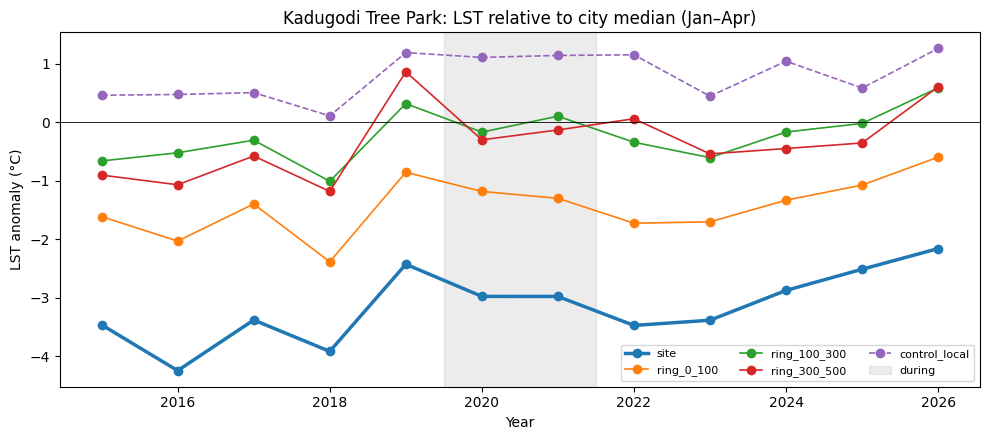

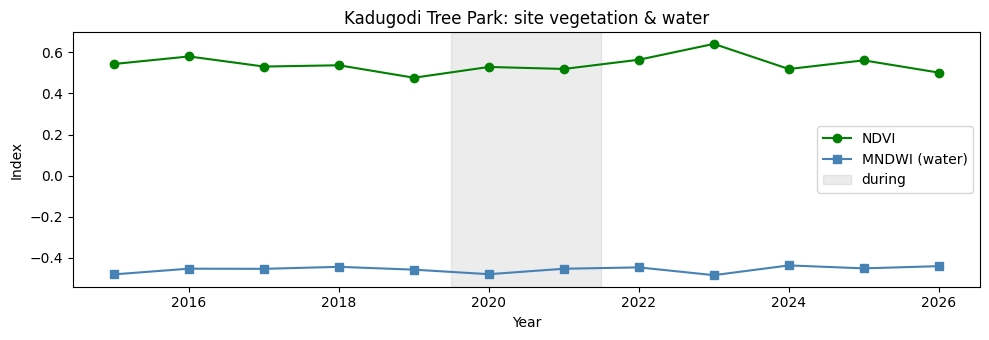

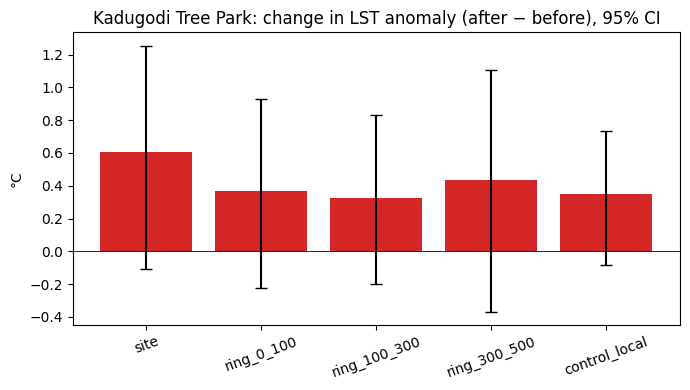

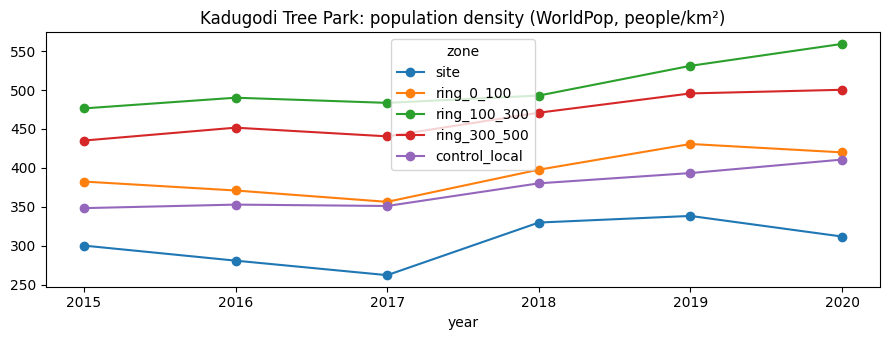

### Before / after maps

Saved map PNGs to figures/


Map(center=[12.999, 77.76], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

### Summary

Kadugodi Tree Park: relative to its 1-2 km neighbourhood, the park's LST changed by +0.10 °C after the project (95% CI -0.37 to +0.57, p = 0.632, 26+50 scenes) - not significant. NDVI change +0.024.


In [17]:
run_site('kadugodi');

## 6. All parks compared + pooled model

The per-park table uses the main scene-level test. The pooled model fits every park at once
(`diff ~ post + C(park)`, standard errors clustered by park-year), which answers the overall question —
*are new parks associated with cooling?* — with far more data than any single park.

did = change in LST relative to the 1-2 km neighbourhood (°C); negative = cooler


,park,status,years,ndvi_change,site_did,site_p,ring_0_100_did,ring_0_100_p,ring_100_300_did,ring_100_300_p,ring_300_500_did,ring_300_500_p
0,Freedom Park,ok,1997-2013,0.138,-1.324,0.052,0.610,0.011,0.875,0.000,0.798,0.000
1,JP Park (Mathikere),ok,1998-2011,-0.000,-0.482,0.749,-0.283,0.552,-0.442,0.059,-0.115,0.635
2,JB Kaval Tree Park (Yelahanka),ok,2009-2020,0.042,1.355,0.017,0.080,0.842,0.532,0.197,0.666,0.034
3,Kadugodi Tree Park,ok,2015-2026,0.024,0.103,0.632,-0.040,0.771,0.083,0.524,0.026,0.875



Pooled model (all parks together):


,zone,parks,scenes,did,ci_low,ci_high,p
0,site,4,198,0.100,-0.584,0.784,0.768
1,ring_0_100,4,199,0.059,-0.232,0.349,0.684
2,ring_100_300,4,203,0.247,-0.031,0.525,0.080
3,ring_300_500,4,202,0.307,0.061,0.553,0.016


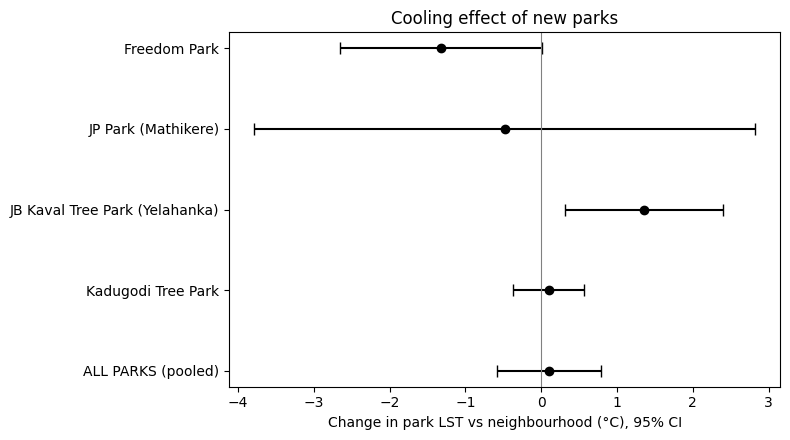

In [18]:
ZONES = ['site', 'ring_0_100', 'ring_100_300', 'ring_300_500']

rows = []
for key, c in RESULTS.items():
    sd = getattr(c, 'scene_did', pd.DataFrame())
    if sd.empty or 'did' not in sd:
        rows.append(dict(park=c.S['name'], status=f"failed at: {getattr(c, 'failed_at', 'scene test')}"))
        continue
    sd = sd.set_index('zone')
    r = dict(park=c.S['name'], status='ok', years=f"{c.year_min}-{c.year_max}",
             ndvi_change=c.pv.loc['site', 'ndvi_change'])
    for z in ZONES:
        if z in sd.index and pd.notna(sd.loc[z].get('did')):
            r[f'{z}_did'] = sd.loc[z, 'did']
            r[f'{z}_p'] = sd.loc[z, 'p']
    rows.append(r)
comparison = pd.DataFrame(rows)
comparison.round(3).to_csv(os.path.join(BASE, 'data/extracted', 'all_parks_comparison.csv'), index=False)
print('did = change in LST relative to the 1-2 km neighbourhood (°C); negative = cooler')
display(comparison.round(3))

# Pooled model across parks
pooled = pd.concat([c.scene_rows.assign(park=k) for k, c in RESULTS.items()
                    if len(getattr(c, 'scene_rows', []))], ignore_index=True)
prow = []
for z in ZONES:
    d = pooled[pooled.zone == z].copy()
    if d.park.nunique() < 2:
        continue
    groups = pd.factorize(d.park + '_' + d.year.astype(str))[0]
    fit = smf.ols('diff ~ post + C(park)', d).fit(cov_type='cluster', cov_kwds={'groups': groups}, use_t=True)
    lo, hi = fit.conf_int().loc['post']
    prow.append(dict(zone=z, parks=d.park.nunique(), scenes=len(d), did=fit.params['post'],
                     ci_low=lo, ci_high=hi, p=fit.pvalues['post']))
pooled_res = pd.DataFrame(prow)
pooled_res.round(4).to_csv(os.path.join(BASE, 'data/extracted', 'pooled_model.csv'), index=False)
print('\nPooled model (all parks together):')
display(pooled_res.round(3))

# Chart: per-park and pooled effect with 95% CI
plot = []
for key, c in RESULTS.items():
    sd = getattr(c, 'scene_did', pd.DataFrame())
    if not sd.empty and 'did' in sd and 'site' in set(sd.zone):
        r = sd.set_index('zone').loc['site']
        if pd.notna(r.get('did')):
            plot.append((c.S['name'], r.did, r.ci_low, r.ci_high))
if len(pooled_res) and 'site' in set(pooled_res.zone):
    r = pooled_res.set_index('zone').loc['site']
    plot.append(('ALL PARKS (pooled)', r.did, r.ci_low, r.ci_high))
if plot:
    names, eff, lo, hi = zip(*plot)
    fig, ax = plt.subplots(figsize=(8, 0.6 * len(plot) + 1.5))
    yy = np.arange(len(plot))[::-1]
    ax.errorbar(eff, yy, xerr=[np.subtract(eff, lo), np.subtract(hi, eff)], fmt='o', capsize=4, color='k')
    ax.axvline(0, color='grey', lw=0.8)
    ax.set_yticks(yy); ax.set_yticklabels(names)
    ax.set(xlabel='Change in park LST vs neighbourhood (°C), 95% CI', title='Cooling effect of new parks')
    plt.tight_layout(); plt.savefig(os.path.join(BASE, 'figures', 'all_parks_effects.png'), dpi=200); plt.show()